# Introduction to Signals – Supporting Code Examples

This notebook provides Python illustrations for the concepts introduced in the slides we looked at in class: continuous-time vs. discrete-time signals, time shifting, scaling, reversal, periodicity, even/odd decomposition, energy/power, and the unit impulse/step.

## Setup: Common Imports

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

# Set plotting style
plt.rcParams['figure.figsize'] = (10, 4)
plt.rcParams['font.size'] = 12

## 1. Continuous-Time vs. Discrete-Time Signals

A continuous-time signal is defined for every instant $t$, while a discrete-time signal is defined only at integer indices $n$.

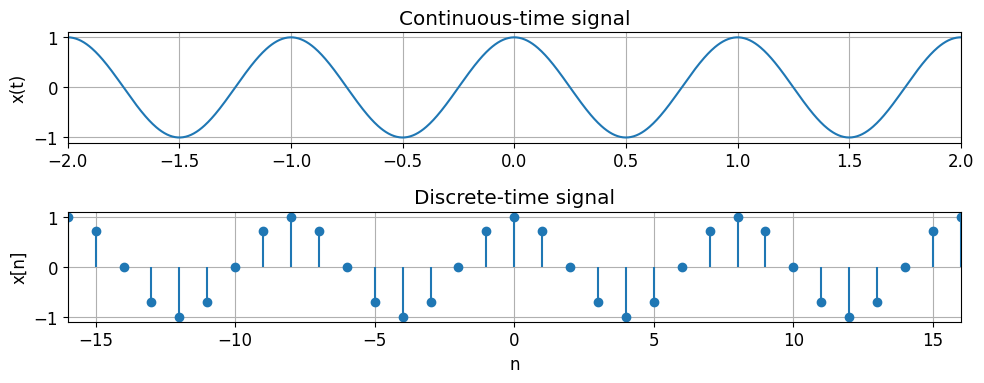

In [13]:
# CT signal: x(t) = cos(2π t)
t = np.linspace(-2, 2, 1000)
x_ct = np.cos(2 * np.pi * t)

# DT signal: x[n] = cos(2π n / 8)  (8 samples per period)
n = np.arange(-16, 17)
x_dt = np.cos(2 * np.pi * n / 8)

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=False)
ax1.plot(t, x_ct)
ax1.set_ylabel('x(t)')
ax1.set_title('Continuous-time signal')
ax1.set_xlim(np.min(t),np.max(t))
ax1.grid(True)

ax2.stem(n, x_dt, basefmt=' ')
ax2.set_xlabel('n')
ax2.set_ylabel('x[n]')
ax2.set_xlim(np.min(n), np.max(n))
ax2.set_title('Discrete-time signal')
ax2.grid(True)

plt.tight_layout()
plt.show()

## 2. Time Shifting and Reversal

We use a triangular pulse to illustrate shifting by $t_0$ and reversal $x(-t)$.

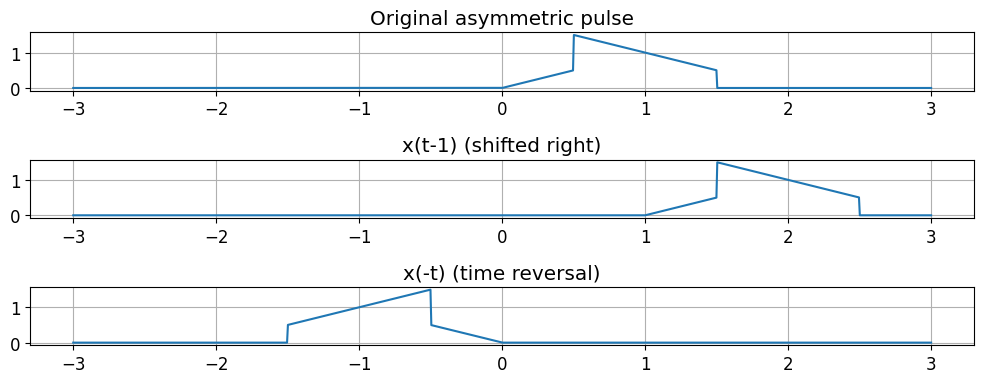

In [14]:
# Define an asymmetric pulse: rises from 0 to 1 on [0,1], falls from 1 to 0 on [1,2]
def asymmetric_pulse(t):
    t = np.asarray(t)
    y = np.zeros_like(t)
    # rising part
    mask_rise = (t >= 0) & (t <= 0.5)
    y[mask_rise] = t[mask_rise]           # linear 0→1
    # falling part
    mask_fall = (t >= 0.5) & (t <= 1.5)
    y[mask_fall] = 2 - t[mask_fall]       # linear 1→0
    return y

t = np.linspace(-3, 3, 1000)
x = asymmetric_pulse(t)

t0 = 1
x_shifted = asymmetric_pulse(t - t0)      # delay by 1
x_reversed = asymmetric_pulse(-t)         # time reversal

plt.subplot(3, 1, 1)
plt.plot(t, x)
plt.title('Original asymmetric pulse')
plt.grid(True)

plt.subplot(3, 1, 2)
plt.plot(t, x_shifted)
plt.title(f'x(t-{t0}) (shifted right)')
plt.grid(True)

plt.subplot(3, 1, 3)
plt.plot(t, x_reversed)
plt.title('x(-t) (time reversal)')
plt.grid(True)

plt.tight_layout()
plt.show()

## 3. Time Scaling

Compression ($a>1$) and expansion ($0<a<1$) of a signal.

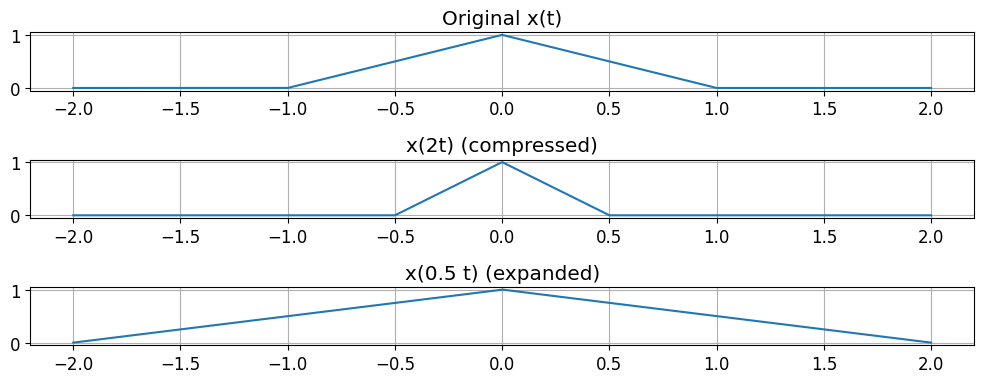

In [15]:
# Define a triangular pulse
def triangle(t):
    return np.maximum(0, 1 - np.abs(t))

t = np.linspace(-2, 2, 1000)
x = triangle(t)

a_compress = 2
x_compress = triangle(a_compress * t)   # compressed

a_expand = 0.5
x_expand = triangle(a_expand * t)       # expanded

plt.subplot(3, 1, 1)
plt.plot(t, x)
plt.title('Original x(t)')
plt.grid(True)

plt.subplot(3, 1, 2)
plt.plot(t, x_compress)
plt.title('x(2t) (compressed)')
plt.grid(True)

plt.subplot(3, 1, 3)
plt.plot(t, x_expand)
plt.title('x(0.5 t) (expanded)')
plt.grid(True)

plt.tight_layout()
plt.show()

## 4. Combined Transformation: $x(\alpha t + \beta)$

We illustrate the systematic approach: shift then scale.

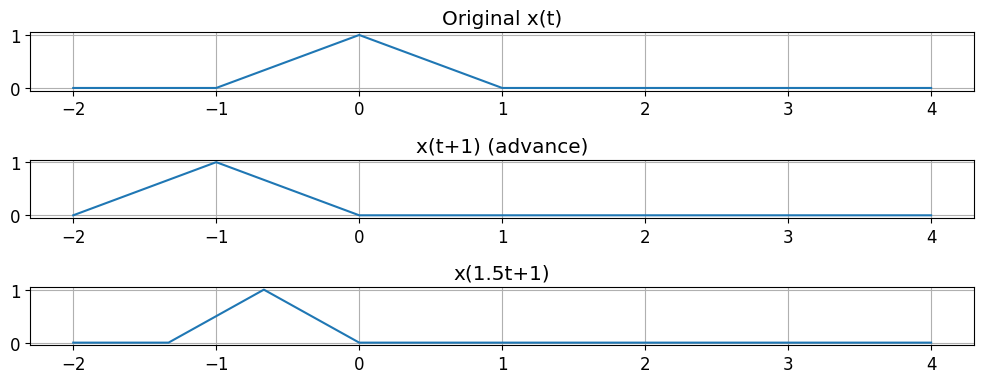

In [16]:
t = np.linspace(-2, 4, 1000)
x = triangle(t)

alpha = 1.5
beta = 1
# Method: first shift x(t+beta), then compress by 1/alpha
x_shifted = triangle(t + beta)
x_combined = triangle(alpha * t + beta)   # directly

plt.subplot(3, 1, 1)
plt.plot(t, x)
plt.title('Original x(t)')
plt.grid(True)

plt.subplot(3, 1, 2)
plt.plot(t, x_shifted)
plt.title(f'x(t+{beta}) (advance)')
plt.grid(True)

plt.subplot(3, 1, 3)
plt.plot(t, x_combined)
plt.title(f'x({alpha}t+{beta})')
plt.grid(True)

plt.tight_layout()
plt.show()

## 5. Periodicity: CT vs. DT

A CT sinusoid is always periodic. A DT sinusoid is periodic only if the frequency is a rational multiple of $2\pi$.

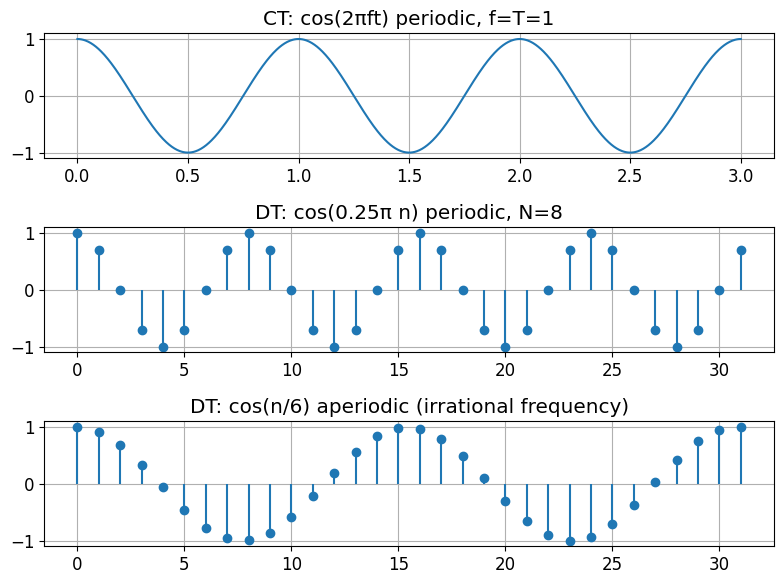

In [17]:
# CT sinusoid: periodic with T=1
t_ct = np.linspace(0, 3, 1000)
x_ct = np.cos(2 * np.pi * t_ct)   # f0=1 Hz, T=1

# DT periodic: cos(0.25π n) → ω0=π/4, ω0/(2π)=1/8 (rational)
n = np.arange(0, 32)
x_dt_per = np.cos(0.25 * np.pi * n)

# DT aperiodic: cos(n/6) → ω0=1/6, ω0/(2π)=1/(12π) (irrational)
x_dt_aper = np.cos(n / np.sqrt(6))

fig, axs = plt.subplots(3, 1, figsize=(8, 6))
axs[0].plot(t_ct, x_ct)
axs[0].set_title('CT: cos(2πft) periodic, f=T=1')
axs[0].grid(True)

axs[1].stem(n, x_dt_per, basefmt=' ')
axs[1].set_title('DT: cos(0.25π n) periodic, N=8')
axs[1].grid(True)

axs[2].stem(n, x_dt_aper, basefmt=' ')
axs[2].set_title('DT: cos(n/6) aperiodic (irrational frequency)')
axs[2].grid(True)

plt.tight_layout()
plt.show()

## 6. Even and Odd Decomposition

Any signal can be split into even and odd parts. Verify that $x_e(t)$ is even, $x_o(t)$ is odd.

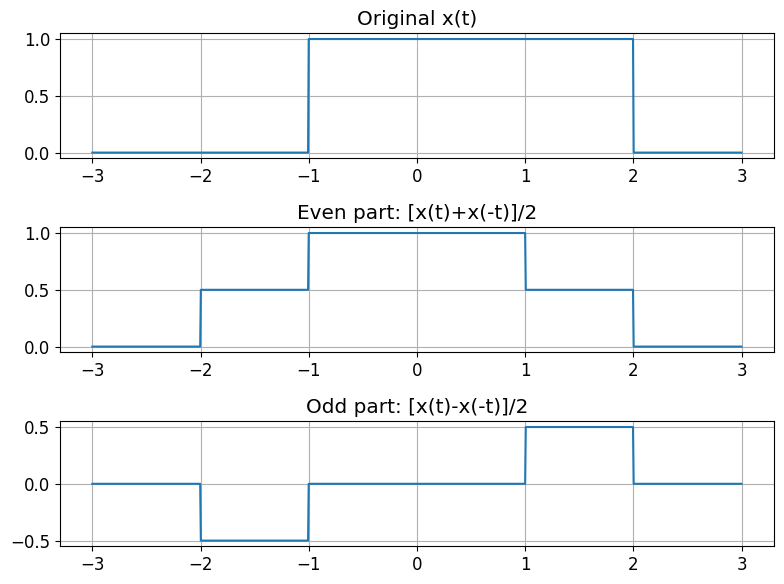

Even part is even? Max difference: 0.00e+00
Odd part is odd?   Max difference: 0.00e+00


In [18]:
# Use a non-symmetric signal: rectangular pulse from -1 to 2
t = np.linspace(-3, 3, 1000)
x = ((t >= -1) & (t <= 2)).astype(float)   # convert to float

# Even and odd parts
x_even = (x + np.flip(x)) / 2
x_odd = (x - np.flip(x)) / 2

fig, axs = plt.subplots(3, 1, figsize=(8, 6))
plt.subplot(3, 1, 1)
plt.plot(t, x)
plt.title('Original x(t)')
plt.grid(True)

plt.subplot(3, 1, 2)
plt.plot(t, x_even)
plt.title('Even part: [x(t)+x(-t)]/2')
plt.grid(True)

plt.subplot(3, 1, 3)
plt.plot(t, x_odd)
plt.title('Odd part: [x(t)-x(-t)]/2')
plt.grid(True)

plt.tight_layout()
plt.show()

# Check symmetry:
print(f"Even part is even? Max difference: {np.max(np.abs(x_even - np.flip(x_even))):.2e}")
print(f"Odd part is odd?   Max difference: {np.max(np.abs(x_odd + np.flip(x_odd))):.2e}")

## 7. Energy and Power of Signals

Compute total energy and average power for a finite-energy pulse (energy signal) and a sinusoid (power signal).

In [19]:
# Energy signal: rectangular pulse from 0 to 2, amplitude 3
t = np.linspace(-1, 3, 10000)
pulse = 3 * ((t >= 0) & (t <= 2)).astype(float)
dt = t[1] - t[0]
energy = np.sum(pulse**2) * dt
print(f"Rectangular pulse (height 3, width 2): Energy = {energy:.2f}")

# Power signal: sinusoid A cos(2π f0 t)
A = 2
f0 = 1
T0 = 1/f0
t_period = np.linspace(0, T0, 1000)
x_sin = A * np.cos(2 * np.pi * f0 * t_period)
power_one_period = np.sum(x_sin**2) * (t_period[1]-t_period[0]) / T0
print(f"Sinusoid A=2, f0=1: Average power = {power_one_period:.2f} (theoretical A^2/2 = {A**2/2})")

# Show that energy over infinite time is infinite
T_long = 100
t_long = np.linspace(0, T_long, 100000)
x_long = A * np.cos(2 * np.pi * f0 * t_long)
energy_long = np.sum(x_long**2) * (t_long[1]-t_long[0])
print(f"Energy over {T_long} seconds: {energy_long:.2f} tends to an infinite value as T tends to an infinite value")

Rectangular pulse (height 3, width 2): Energy = 18.00
Sinusoid A=2, f0=1: Average power = 2.00 (theoretical A^2/2 = 2.0)
Energy over 100 seconds: 200.00 tends to an infinite value as T tends to an infinite value


## 8. Unit Step and Unit Impulse

The unit step $u(t)$ is the integral of the impulse $\delta(t)$. The impulse can be approximated by a narrow pulse of unit area.

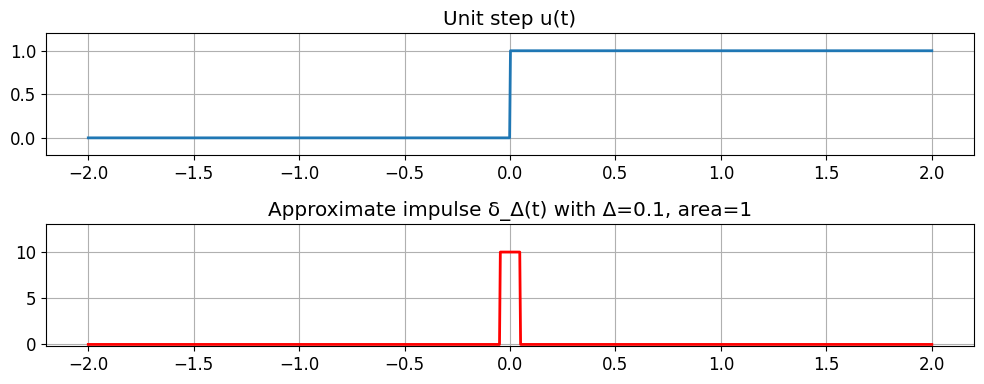

Sifting property: ∫ e^[ 2.          1.995996    1.99199199  1.98798799  1.98398398  1.97997998
  1.97597598  1.97197197  1.96796797  1.96396396  1.95995996  1.95595596
  1.95195195  1.94794795  1.94394394  1.93993994  1.93593594  1.93193193
  1.92792793  1.92392392  1.91991992  1.91591592  1.91191191  1.90790791
  1.9039039   1.8998999   1.8958959   1.89189189  1.88788789  1.88388388
  1.87987988  1.87587588  1.87187187  1.86786787  1.86386386  1.85985986
  1.85585586  1.85185185  1.84784785  1.84384384  1.83983984  1.83583584
  1.83183183  1.82782783  1.82382382  1.81981982  1.81581582  1.81181181
  1.80780781  1.8038038   1.7997998   1.7957958   1.79179179  1.78778779
  1.78378378  1.77977978  1.77577578  1.77177177  1.76776777  1.76376376
  1.75975976  1.75575576  1.75175175  1.74774775  1.74374374  1.73973974
  1.73573574  1.73173173  1.72772773  1.72372372  1.71971972  1.71571572
  1.71171171  1.70770771  1.7037037   1.6996997   1.6956957   1.69169169
  1.68768769  1.68368368  1.6

In [20]:
# Unit step
t = np.linspace(-2, 2, 1000)
u = (t >= 0).astype(float)

# Approximate impulse as a narrow rectangle (width Δ, height 1/Δ)
Delta = 0.1
impulse_approx = ((t >= -Delta/2) & (t <= Delta/2)).astype(float) / Delta

plt.subplot(2, 1, 1)
plt.plot(t, u, linewidth=2)
plt.title('Unit step u(t)')
plt.grid(True)
plt.ylim(-0.2, 1.2)

plt.subplot(2, 1, 2)
plt.plot(t, impulse_approx, 'r', linewidth=2)
plt.title(f'Approximate impulse δ_Δ(t) with Δ={Delta}, area=1')
plt.grid(True)
plt.ylim(-0.2, 1.2/Delta + 1)

plt.tight_layout()
plt.show()

# Verify sifting property numerically
def sifting_test(phi_func, t0, Delta=0.01):
    t = np.linspace(t0-0.5, t0+0.5, 100000)
    delta_approx = ((t >= t0-Delta/2) & (t <= t0+Delta/2)).astype(float) / Delta
    integral = np.sum(phi_func(t) * delta_approx) * (t[1]-t[0])
    return integral

phi = lambda t: np.exp(-t) # an anonymous functions 
t0 = 1.5
result = sifting_test(phi, t0)
print(f"Sifting property: ∫ e^{-t} δ(t-{t0}) dt ≈ {result:.5f} (should be e^{-t0} = {np.exp(-t0):.5f})")

## 9. The Complex Exponential Signal

Plot real and imaginary parts of $e^{j\omega_0 t}$ and its magnitude/phase.

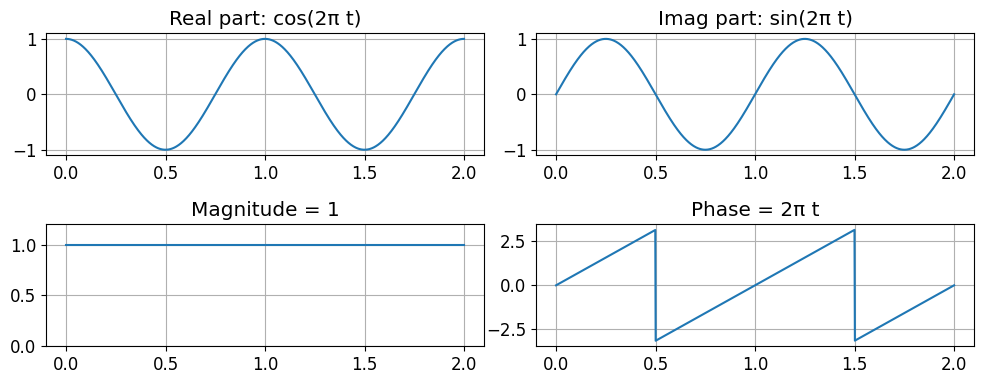

In [21]:
f0 = 1
omega0 = 2 * np.pi * f0
t = np.linspace(0, 2, 1000)
x_complex = np.exp(1j * omega0 * t)

plt.subplot(2, 2, 1)
plt.plot(t, np.real(x_complex))
plt.title('Real part: cos(2π t)')
plt.grid(True)

plt.subplot(2, 2, 2)
plt.plot(t, np.imag(x_complex))
plt.title('Imag part: sin(2π t)')
plt.grid(True)

plt.subplot(2, 2, 3)
plt.plot(t, np.abs(x_complex))
plt.title('Magnitude = 1')
plt.grid(True)
plt.ylim(0, 1.2)

plt.subplot(2, 2, 4)
plt.plot(t, np.angle(x_complex))
plt.title('Phase = 2π t')
plt.grid(True)

plt.tight_layout()
plt.show()

## 10. Damped Sinusoid (Decaying Exponential × Sinusoid)

Illustrates the natural response of an RLC circuit or a mechanical system with damping.

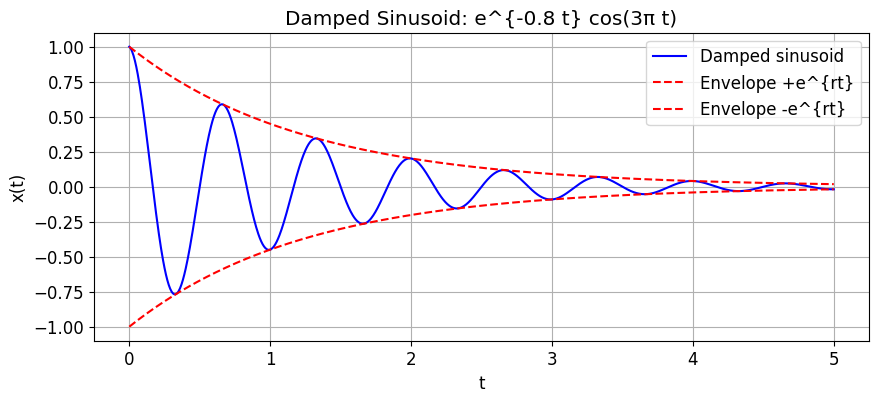

In [22]:
t = np.linspace(0, 5, 1000)
r = -0.8   # decay factor (negative exponent)
omega0 = 2 * np.pi * 1.5
phi = 0
A = 1

x = A * np.exp(r * t) * np.cos(omega0 * t + phi)
envelope_plus = A * np.exp(r * t)
envelope_minus = -A * np.exp(r * t)

plt.plot(t, x, 'b-', label='Damped sinusoid')
plt.plot(t, envelope_plus, 'r--', label='Envelope +e^{rt}')
plt.plot(t, envelope_minus, 'r--', label='Envelope -e^{rt}')
plt.xlabel('t')
plt.ylabel('x(t)')
plt.title('Damped Sinusoid: e^{-0.8 t} cos(3π t)')
plt.grid(True)
plt.legend()
plt.show()

## 11. Discrete-Time Complex Exponential: Periodicity Condition

Demonstrate that $e^{j\omega_0 n}$ repeats only when $\omega_0/(2\pi)$ is rational.

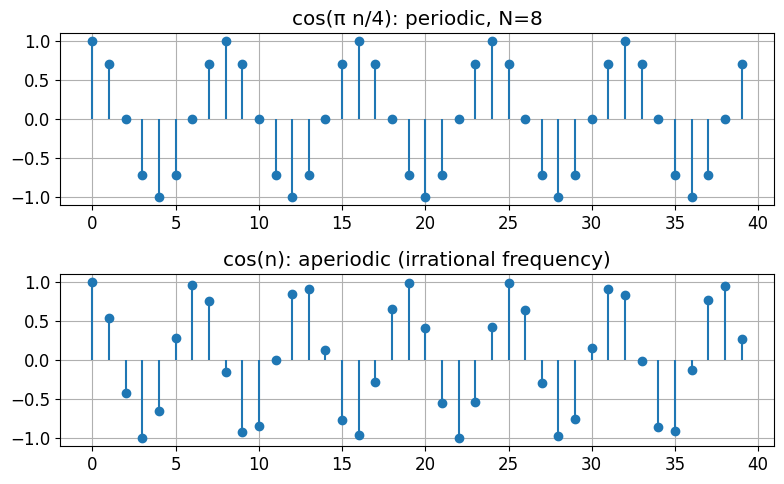

In [23]:
n = np.arange(0, 40)

# Rational ω0 = π/4 → ω0/(2π)=1/8, period N=8
omega1 = np.pi/4
x1 = np.cos(omega1 * n)

# Irrational ω0 = 1 rad → ω0/(2π)=1/(2π) irrational
omega2 = 1.0
x2 = np.cos(omega2 * n)

fig, axs = plt.subplots(2, 1, figsize=(8, 5))
axs[0].stem(n, x1, basefmt=' ')
axs[0].set_title('cos(π n/4): periodic, N=8')
axs[0].grid(True)

axs[1].stem(n, x2, basefmt=' ')
axs[1].set_title('cos(n): aperiodic (irrational frequency)')
axs[1].grid(True)

plt.tight_layout()
plt.show()